In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import networkx as nx
import scipy
import shapely
import pyproj

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Folium:", folium.__version__)
print("NetworkX:", nx.__version__)

print("\nAll M1 libraries imported successfully!")

Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python executable: D:\PathSnap\.venv\Scripts\python.exe
NumPy: 2.5.5
Pandas: 3.1.1
Folium: 1.0.0
NetworkX: 3.7

All M1 libraries imported successfully!


In [2]:

from pathlib import Path

ROOT = Path.cwd()
DATA_DIR = ROOT / "dataset"

PARTITIONS = ["train", "student_test"]
EXTENSIONS = [".track", ".nodes", ".arcs", ".route"]

print("PROJECT ROOT:", ROOT)
print("DATASET PATH:", DATA_DIR)
print("=" * 60)

for partition in PARTITIONS:
    folder = DATA_DIR / partition

    if not folder.exists():
        print(f"\nERROR: {partition} folder not found!")
        continue

    trips = sorted(
        p for p in folder.iterdir() if p.is_dir()
    )

    print(f"\nPARTITION: {partition}")
    print("Number of trips:", len(trips))

    complete = 0
    incomplete = []

    for trip in trips:
        missing = [
            ext for ext in EXTENSIONS
            if not (trip / f"{trip.name}{ext}").is_file()
        ]

        if missing:
            incomplete.append((trip.name, missing))
        else:
            complete += 1

    print("Complete trips:", complete)
    print("Incomplete trips:", len(incomplete))

    if incomplete:
        print("Missing files:", incomplete[:10])

print("\n" + "=" * 60)
print("SAMPLE FILE CONTENTS")
print("=" * 60)

sample_trip = next(
    p for p in (DATA_DIR / "train").iterdir()
    if p.is_dir()
)

print("Sample trip ID:", sample_trip.name)

for ext in EXTENSIONS:
    file_path = sample_trip / f"{sample_trip.name}{ext}"

    print(f"\n--- {ext} ---")

    if file_path.exists():
        with file_path.open(
            "r", encoding="utf-8", errors="replace"
        ) as f:
            for _ in range(5):
                line = f.readline()
                if not line:
                    break
                print(line.rstrip())
    else:
        print("File missing!")


PROJECT ROOT: D:\PathSnap
DATASET PATH: D:\PathSnap\dataset

PARTITION: train
Number of trips: 80
Complete trips: 80
Incomplete trips: 0

PARTITION: student_test
Number of trips: 10
Complete trips: 10
Incomplete trips: 0

SAMPLE FILE CONTENTS
Sample trip ID: 00000001

--- .track ---
8.595203	49.844053	1.000000
8.595294	49.844441	2.000000
8.595352	49.844883	3.000000
8.595390	49.845379	4.000000
8.595587	49.845750	5.000000

--- .nodes ---
8.581679	49.857880
8.584637	49.858295
8.580173	49.858567
8.584392	49.859119
8.584935	49.857396

--- .arcs ---
0	281
0	1
0	5
1	0
1	40750

--- .route ---
2641
64973
133948
133949
139208


In [3]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd() / "dataset"

def inspect_trip(trip_dir):
    trip_id = trip_dir.name

    track = pd.read_csv(
        trip_dir / f"{trip_id}.track",
        sep=r"\s+", header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    nodes = pd.read_csv(
        trip_dir / f"{trip_id}.nodes",
        sep=r"\s+", header=None,
        names=["longitude", "latitude"]
    )

    arcs = pd.read_csv(
        trip_dir / f"{trip_id}.arcs",
        sep=r"\s+", header=None,
        names=["from_node_id", "to_node_id"]
    )

    route = pd.read_csv(
        trip_dir / f"{trip_id}.route",
        header=None, names=["arc_id"]
    )

    return {
        "trip_id": trip_id,
        "gps_observations": len(track),
        "road_nodes": len(nodes),
        "road_arcs": len(arcs),
        "route_arcs": len(route),
        "missing_gps": track.isna().sum().sum(),
        "duplicate_gps": track.duplicated().sum(),
        "invalid_coordinates": (
            ~track["longitude"].between(-180, 180) |
            ~track["latitude"].between(-90, 90)
        ).sum(),
        "timestamp_gaps": (
            track["timestamp"].diff().dropna() > 1
        ).sum(),
        "timestamp_reversals": (
            track["timestamp"].diff().dropna() <= 0
        ).sum(),
        "longitude_min": track["longitude"].min(),
        "longitude_max": track["longitude"].max(),
        "latitude_min": track["latitude"].min(),
        "latitude_max": track["latitude"].max(),
    }


results = {}

for partition in ["train", "student_test"]:
    trip_dirs = sorted(
        p for p in (DATA_DIR / partition).iterdir()
        if p.is_dir()
    )

    results[partition] = pd.DataFrame(
        [inspect_trip(p) for p in trip_dirs]
    )

    print(f"\n{'='*60}")
    print(f"{partition.upper()} SUMMARY")
    print("="*60)

    print("Trips:", len(results[partition]))
    print("Total GPS observations:",
          results[partition]["gps_observations"].sum())
    print("Total road nodes:",
          results[partition]["road_nodes"].sum())
    print("Total road arcs:",
          results[partition]["road_arcs"].sum())
    print("Total reference route entries:",
          results[partition]["route_arcs"].sum())

    print("\nData quality:")
    print(results[partition][[
        "missing_gps",
        "duplicate_gps",
        "invalid_coordinates",
        "timestamp_gaps",
        "timestamp_reversals"
    ]].sum())

print("\nAnalysis completed.")



TRAIN SUMMARY
Trips: 80
Total GPS observations: 208417
Total road nodes: 1933485
Total road arcs: 3876904
Total reference route entries: 31336

Data quality:
missing_gps               0
duplicate_gps             0
invalid_coordinates       0
timestamp_gaps         7286
timestamp_reversals       0
dtype: int64

STUDENT_TEST SUMMARY
Trips: 10
Total GPS observations: 19160
Total road nodes: 90689
Total road arcs: 185041
Total reference route entries: 3477

Data quality:
missing_gps              0
duplicate_gps            0
invalid_coordinates      0
timestamp_gaps         264
timestamp_reversals      0
dtype: int64

Analysis completed.


In [4]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd() / "dataset"

quality_results = []

for partition in ["train", "student_test"]:
    for trip_dir in sorted((DATA_DIR / partition).iterdir()):
        if not trip_dir.is_dir():
            continue

        tid = trip_dir.name

        track = pd.read_csv(
            trip_dir / f"{tid}.track",
            sep=r"\s+", header=None,
            names=["lon", "lat", "timestamp"]
        )

        nodes = pd.read_csv(
            trip_dir / f"{tid}.nodes",
            sep=r"\s+", header=None,
            names=["lon", "lat"]
        )

        arcs = pd.read_csv(
            trip_dir / f"{tid}.arcs",
            sep=r"\s+", header=None,
            names=["source", "target"]
        )

        route = pd.read_csv(
            trip_dir / f"{tid}.route",
            header=None, names=["arc_id"]
        )

        dt = track["timestamp"].diff().dropna()

        quality_results.append({
            "partition": partition,
            "trip_id": tid,
            "min_interval": dt.min() if len(dt) else None,
            "max_interval": dt.max() if len(dt) else None,
            "mean_interval": dt.mean() if len(dt) else None,
            "negative_intervals": (dt < 0).sum(),
            "zero_intervals": (dt == 0).sum(),
            "invalid_arc_nodes": (
                (arcs["source"] >= len(nodes)) |
                (arcs["target"] >= len(nodes)) |
                (arcs["source"] < 0) |
                (arcs["target"] < 0)
            ).sum(),
            "invalid_route_arcs": (
                (route["arc_id"] < 0) |
                (route["arc_id"] >= len(arcs))
            ).sum()
        })

quality_df = pd.DataFrame(quality_results)

print("TIMESTAMP INTERVALS")
display(quality_df.groupby("partition")[
    ["min_interval", "max_interval", "mean_interval"]
].agg(["min", "max", "mean"]))

print("\nINVALID ROAD REFERENCES")
display(quality_df.groupby("partition")[
    ["invalid_arc_nodes", "invalid_route_arcs"]
].sum())

print("\nTRIPS WITH TIMESTAMP ANOMALIES")
display(quality_df[
    (quality_df["zero_intervals"] > 0) |
    (quality_df["negative_intervals"] > 0)
])


TIMESTAMP INTERVALS


min_interval           max_interval                    \
                      min  max mean          min       max    mean   
partition                                                            
student_test          1.0  1.0  1.0          1.0     210.0    25.5   
train                 1.0  1.0  1.0          1.0  153064.0  2706.4   

             mean_interval                        
                       min         max      mean  
partition                                         
student_test           1.0    1.525926  1.090549  
train                  1.0  287.906542  5.101888


INVALID ROAD REFERENCES


,invalid_arc_nodes,invalid_route_arcs
partition,,
student_test,0,0
train,0,0



TRIPS WITH TIMESTAMP ANOMALIES


,partition,trip_id,min_interval,max_interval,mean_interval,negative_intervals,zero_intervals,invalid_arc_nodes,invalid_route_arcs


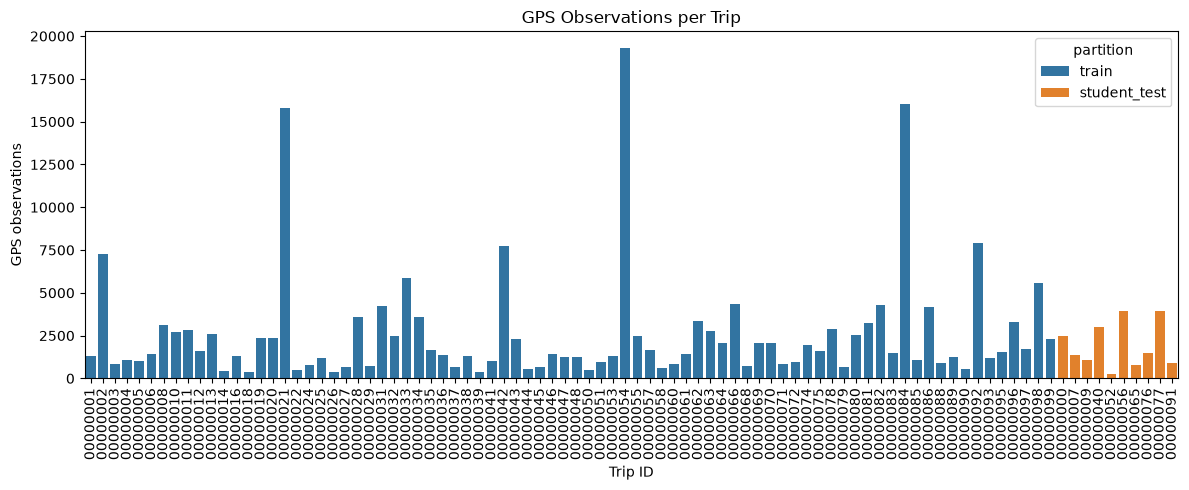

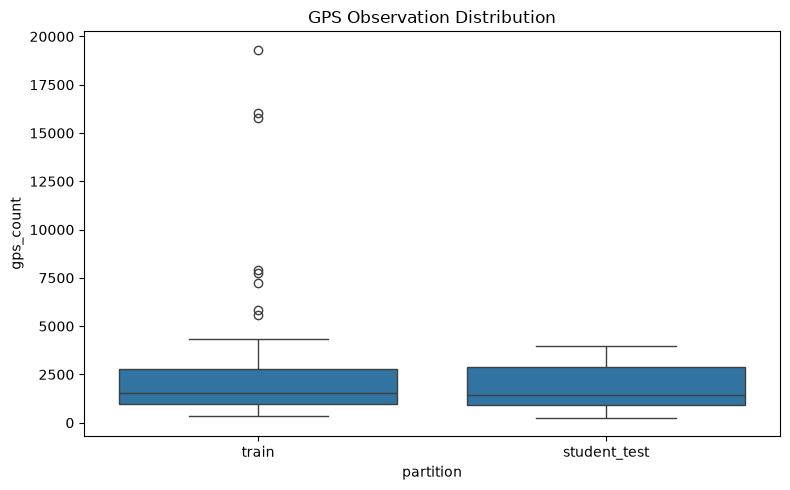

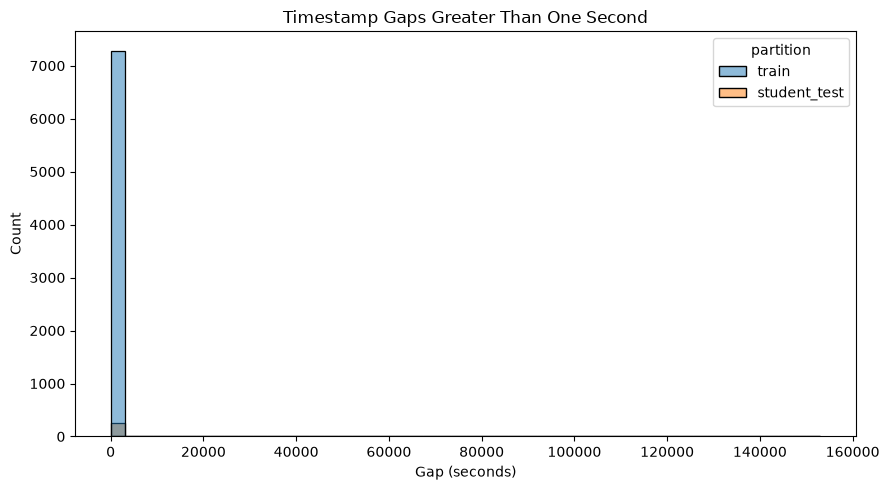

TOP 15 LARGEST TIMESTAMP GAPS


,partition,trip_id,timestamp_index,gap_seconds
5961,train,00000090,535,153064.0
3949,train,00000078,2,52810.0
3631,train,00000069,986,2658.0
931,train,00000021,7869,2161.0
716,train,00000011,1601,909.0
3611,train,00000069,844,816.0
2507,train,00000042,1892,670.0
928,train,00000021,184,660.0
2563,train,00000042,7251,585.0
5549,train,00000081,2777,536.0



EDA files saved in: D:\PathSnap\results\m1
Folium map saved in: D:\PathSnap\results\m1\maps
Trip statistics: 90
Timestamp gaps identified: 7550


In [5]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

DATA_DIR = Path.cwd() / "dataset"
OUTPUT = Path.cwd() / "results" / "m1"
PLOTS = OUTPUT / "plots"
MAPS = OUTPUT / "maps"

PLOTS.mkdir(parents=True, exist_ok=True)
MAPS.mkdir(parents=True, exist_ok=True)

# 1. Collect trip statistics
records = []
gap_records = []

for partition in ["train", "student_test"]:
    for folder in sorted((DATA_DIR / partition).iterdir()):
        if not folder.is_dir():
            continue

        tid = folder.name

        track = pd.read_csv(
            folder / f"{tid}.track",
            sep=r"\s+", header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        gaps = track["timestamp"].diff().dropna()

        records.append({
            "partition": partition,
            "trip_id": tid,
            "gps_count": len(track),
            "node_count": sum(1 for _ in open(folder / f"{tid}.nodes")),
            "arc_count": sum(1 for _ in open(folder / f"{tid}.arcs")),
            "route_count": sum(1 for _ in open(folder / f"{tid}.route")),
            "mean_interval": gaps.mean() if len(gaps) else 0,
            "max_gap": gaps.max() if len(gaps) else 0
        })

        for index, gap in gaps.items():
            if gap > 1:
                gap_records.append({
                    "partition": partition,
                    "trip_id": tid,
                    "timestamp_index": index,
                    "gap_seconds": gap
                })

stats = pd.DataFrame(records)
gaps_df = pd.DataFrame(gap_records)

stats.to_csv(OUTPUT / "trip_statistics.csv", index=False)
gaps_df.to_csv(OUTPUT / "timestamp_gaps.csv", index=False)

# 2. GPS observations per trip
plt.figure(figsize=(12, 5))
sns.barplot(data=stats, x="trip_id", y="gps_count",
            hue="partition", dodge=False)
plt.title("GPS Observations per Trip")
plt.xlabel("Trip ID")
plt.ylabel("GPS observations")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(PLOTS / "gps_observations_per_trip.png", dpi=150)
plt.show()

# 3. GPS observation distribution
plt.figure(figsize=(8, 5))
sns.boxplot(data=stats, x="partition", y="gps_count")
plt.title("GPS Observation Distribution")
plt.tight_layout()
plt.savefig(PLOTS / "gps_observation_distribution.png", dpi=150)
plt.show()

# 4. Timestamp gap distribution (exclude 1-second intervals)
if not gaps_df.empty:
    plt.figure(figsize=(9, 5))
    sns.histplot(
        data=gaps_df, x="gap_seconds",
        hue="partition", bins=50
    )
    plt.title("Timestamp Gaps Greater Than One Second")
    plt.xlabel("Gap (seconds)")
    plt.tight_layout()
    plt.savefig(PLOTS / "timestamp_gap_distribution.png", dpi=150)
    plt.show()

# 5. Identify largest timestamp gaps
print("TOP 15 LARGEST TIMESTAMP GAPS")
display(gaps_df.nlargest(15, "gap_seconds"))

# 6. Folium map of one training trip
trip_id = "00000001"
folder = DATA_DIR / "train" / trip_id

track = pd.read_csv(
    folder / f"{trip_id}.track",
    sep=r"\s+", header=None,
    names=["longitude", "latitude", "timestamp"]
)

nodes = pd.read_csv(
    folder / f"{trip_id}.nodes",
    sep=r"\s+", header=None,
    names=["longitude", "latitude"]
)

arcs = pd.read_csv(
    folder / f"{trip_id}.arcs",
    sep=r"\s+", header=None,
    names=["source", "target"]
)

center = [
    track["latitude"].mean(),
    track["longitude"].mean()
]

m = folium.Map(
    location=center,
    zoom_start=14,
    tiles=None
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri World Street Map"
).add_to(m)

# GPS trajectory
gps_points = track[["latitude", "longitude"]].values.tolist()

folium.PolyLine(
    gps_points, color="blue", weight=4,
    tooltip="GPS trajectory"
).add_to(m)

# Start and end
folium.Marker(
    gps_points[0], tooltip="Start",
    icon=folium.Icon(color="green")
).add_to(m)

folium.Marker(
    gps_points[-1], tooltip="End",
    icon=folium.Icon(color="red")
).add_to(m)

# Road network (limit displayed edges for browser performance)
sampled_arcs = arcs.iloc[::max(1, len(arcs)//5000)]

for row in sampled_arcs.itertuples(index=False):
    u, v = int(row.source), int(row.target)

    if u < len(nodes) and v < len(nodes):
        folium.PolyLine(
            [
                [nodes.iloc[u]["latitude"],
                 nodes.iloc[u]["longitude"]],
                [nodes.iloc[v]["latitude"],
                 nodes.iloc[v]["longitude"]]
            ],
            color="gray", weight=1, opacity=0.35
        ).add_to(m)

m.save(str(MAPS / f"trip_{trip_id}_map.html"))

print("\nEDA files saved in:", OUTPUT)
print("Folium map saved in:", MAPS)
print("Trip statistics:", len(stats))
print("Timestamp gaps identified:", len(gaps_df))


In [6]:

import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from pathlib import Path

DATA_DIR = Path.cwd() / "dataset"

connectivity_results = []

for partition in ["train", "student_test"]:
    for folder in sorted((DATA_DIR / partition).iterdir()):
        if not folder.is_dir():
            continue

        tid = folder.name

        nodes = pd.read_csv(
            folder / f"{tid}.nodes",
            sep=r"\s+", header=None,
            names=["longitude", "latitude"]
        )

        arcs = pd.read_csv(
            folder / f"{tid}.arcs",
            sep=r"\s+", header=None,
            names=["source", "target"]
        )

        n = len(nodes)

        adjacency = coo_matrix(
            (
                np.ones(len(arcs), dtype=np.uint8),
                (arcs["source"], arcs["target"])
            ),
            shape=(n, n)
        ).tocsr()

        component_count, labels = connected_components(
            adjacency,
            directed=False,
            return_labels=True
        )

        degree = np.asarray(adjacency.getnnz(axis=0)).ravel() + \
                 np.asarray(adjacency.getnnz(axis=1)).ravel()

        component_sizes = np.bincount(labels)

        connectivity_results.append({
            "partition": partition,
            "trip_id": tid,
            "nodes": n,
            "arcs": len(arcs),
            "isolated_nodes": int((degree == 0).sum()),
            "connected_components": component_count,
            "largest_component": int(component_sizes.max()),
            "largest_component_percentage": (
                component_sizes.max() / n * 100 if n else 0
            )
        })

connectivity_df = pd.DataFrame(connectivity_results)

display(connectivity_df)

print("\nPARTITION SUMMARY")
display(
    connectivity_df.groupby("partition").agg({
        "nodes": "sum",
        "arcs": "sum",
        "isolated_nodes": "sum",
        "connected_components": "sum",
        "largest_component_percentage": "mean"
    })
)

output = Path.cwd() / "results" / "m1"
connectivity_df.to_csv(
    output / "road_network_connectivity.csv",
    index=False
)

print("Connectivity analysis saved successfully.")


,partition,trip_id,nodes,arcs,isolated_nodes,connected_components,largest_component,largest_component_percentage
0,train,00000001,88809,165790,0,175,86854,97.798647
1,train,00000002,7936,16139,0,14,7750,97.656250
2,train,00000003,9138,18028,0,42,8625,94.386080
3,train,00000004,7350,15499,0,12,7254,98.693878
4,train,00000005,898,1579,0,3,888,98.886414
...,...,...,...,...,...,...,...,...
85,student_test,00000056,14759,27631,0,24,14427,97.750525
86,student_test,00000065,6448,13184,0,5,6388,99.069479
87,student_test,00000076,26635,56027,0,40,25629,96.223015
88,student_test,00000077,4424,9622,0,11,4297,97.129295



PARTITION SUMMARY


,nodes,arcs,isolated_nodes,connected_components,largest_component_percentage
partition,,,,,
student_test,90689,185041,0,227,96.391799
train,1933485,3876904,0,3121,96.896342


Connectivity analysis saved successfully.


In [7]:
from pathlib import Path
from src.data_loader import load_partition
from src.data_validator import validate_trip

ROOT = Path.cwd()
DATA_DIR = ROOT / "dataset"

train = load_partition(DATA_DIR, "train")
student_test = load_partition(DATA_DIR, "student_test")

print("Training trips:", len(train))
print("Student testing trips:", len(student_test))

print("\nSample loaded trip:")
print(train[0]["trip_id"])

print("\nValidation:")
print(validate_trip(train[0]))

Training trips: 80
Student testing trips: 10

Sample loaded trip:
00000001

Validation:
{'trip_id': '00000001', 'missing_gps': 0, 'duplicate_gps': 0, 'invalid_coordinates': 0, 'timestamp_reversals': 0, 'zero_timestamp_intervals': 0, 'timestamp_gaps': 25, 'invalid_arc_nodes': 0, 'invalid_route_arcs': 0, 'valid': True, 'has_timestamp_gaps': True}


In [8]:
import importlib
import src.data_validator as validator

importlib.reload(validator)

print(validator.validate_trip(train[0]))

{'trip_id': '00000001', 'missing_gps': 0, 'duplicate_gps': 0, 'invalid_coordinates': 0, 'timestamp_reversals': 0, 'zero_timestamp_intervals': 0, 'timestamp_gaps': 25, 'invalid_arc_nodes': 0, 'invalid_route_arcs': 0, 'valid': True, 'has_timestamp_gaps': True}


In [9]:
from pathlib import Path
import webbrowser

map_path = (
    Path.cwd() / "results" / "m1" / "maps"
    / "trip_00000001_map.html"
)

webbrowser.open(map_path.resolve().as_uri())

True